In [1]:
print("Cognitive Library Assistant")
print("Project setup successful!")

Cognitive Library Assistant
Project setup successful!


In [2]:
!pip install pandas numpy scikit-learn nltk matplotlib

   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
    --------------------------------------- 0.0/1.8 MB 667.8 kB/s eta 0:00:03
   - -------------------------------------- 0.1/1.8 MB 563.7 kB/s eta 0:00:04
   --- ------------------------------------ 0.1/1.8 MB 853.3 kB/s eta 0:00:02
   ---- ----------------------------------- 0.2/1.8 MB 857.5 kB/s eta 0:00:02
   ---- ----------------------------------- 0.2/1.8 MB 892.5 kB/s eta 0:00:02
   ---- ----------------------------------- 0.2/1.8 MB 892.5 kB/s eta 0:00:02
   ------- -------------------------------- 0.3/1.8 MB 955.3 kB/s eta 0:00:02
   -------- ------------------------------- 0.4/1.8 MB 1.0 MB/s eta 0:00:02
   --------- --------------------


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

import nltk
import matplotlib.pyplot as plt

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
import pandas as pd

books = {
    "Book_ID": [
        "B001", "B002", "B003", "B004", "B005",
        "B006", "B007", "B008", "B009", "B010",
        "B011", "B012", "B013", "B014", "B015"
    ],

    "Title": [
        "Python for Data Analysis",
        "Hands-On Machine Learning",
        "Database System Concepts",
        "Deep Learning",
        "Introduction to Algorithms",
        "Clean Code",
        "Artificial Intelligence: A Modern Approach",
        "The Data Warehouse Toolkit",
        "Learning SQL",
        "Statistics for Data Science",
        "Computer Networks",
        "Operating System Concepts",
        "Power BI for Beginners",
        "Natural Language Processing with Python",
        "Practical Data Science"
    ],

    "Author": [
        "Wes McKinney",
        "Aurélien Géron",
        "Abraham Silberschatz",
        "Ian Goodfellow",
        "Thomas H. Cormen",
        "Robert C. Martin",
        "Stuart Russell",
        "Ralph Kimball",
        "Alan Beaulieu",
        "Andrew Bruce",
        "Andrew S. Tanenbaum",
        "Abraham Silberschatz",
        "Mike Carlo",
        "Steven Bird",
        "Nina Zumel"
    ],

    "Subject": [
        "Data Science",
        "Machine Learning",
        "DBMS",
        "Deep Learning",
        "Algorithms",
        "Programming",
        "Artificial Intelligence",
        "Data Warehousing",
        "SQL",
        "Statistics",
        "Computer Networks",
        "Operating Systems",
        "Data Analytics",
        "NLP",
        "Data Science"
    ],

    "Description": [
        "Learn Python programming for data manipulation, analysis and visualization.",
        "Learn machine learning using practical Python examples and real datasets.",
        "Learn database systems, SQL, transactions and database architecture.",
        "Learn neural networks, deep learning and modern machine learning techniques.",
        "Learn algorithms, data structures and algorithm analysis.",
        "Learn clean programming practices and writing maintainable software.",
        "Learn artificial intelligence, intelligent agents and problem solving.",
        "Learn data warehouse design, dimensional modeling and business intelligence.",
        "Learn SQL queries, database operations and data retrieval.",
        "Learn statistics and probability concepts used in data science.",
        "Learn computer networking, protocols and network architecture.",
        "Learn operating system concepts, processes, memory and file systems.",
        "Learn Power BI, dashboards, reports and business analytics.",
        "Learn natural language processing and text analysis using Python.",
        "Learn practical data science techniques, analysis and machine learning."
    ],

    "Keywords": [
        "Python Pandas NumPy Data Analysis Visualization",
        "Machine Learning Python Regression Classification",
        "Database SQL DBMS Transactions",
        "Deep Learning Neural Networks CNN AI",
        "Algorithms Data Structures Programming",
        "Programming Software Development Code Quality",
        "Artificial Intelligence AI Machine Learning Agents",
        "Data Warehouse Business Intelligence ETL",
        "SQL Database Queries Data Retrieval",
        "Statistics Probability Data Science",
        "Networking TCP IP Internet Protocols",
        "Operating Systems Processes Memory Linux",
        "Power BI Dashboard Data Visualization Analytics",
        "NLP Text Processing Python Language",
        "Data Science Python Machine Learning Analytics"
    ],

    "Difficulty": [
        "Beginner",
        "Intermediate",
        "Intermediate",
        "Advanced",
        "Intermediate",
        "Beginner",
        "Advanced",
        "Intermediate",
        "Beginner",
        "Beginner",
        "Intermediate",
        "Intermediate",
        "Beginner",
        "Intermediate",
        "Beginner"
    ],

    "Year": [
        2022, 2022, 2019, 2016, 2022,
        2008, 2020, 2002, 2020, 2020,
        2011, 2018, 2023, 2009, 2020
    ],

    "Available": [
        "Yes", "Yes", "No", "Yes", "Yes",
        "Yes", "No", "Yes", "Yes", "Yes",
        "No", "Yes", "Yes", "Yes", "Yes"
    ]
}

df = pd.DataFrame(books)

print("Dataset created successfully!")

Dataset created successfully!


In [5]:
df

,Book_ID,Title,Author,Subject,Description,Keywords,Difficulty,Year,Available
0,B001,Python for Data Analysis,Wes McKinney,Data Science,Learn Python programming for data manipulation...,Python Pandas NumPy Data Analysis Visualization,Beginner,2022,Yes
1,B002,Hands-On Machine Learning,Aurélien Géron,Machine Learning,Learn machine learning using practical Python ...,Machine Learning Python Regression Classification,Intermediate,2022,Yes
2,B003,Database System Concepts,Abraham Silberschatz,DBMS,"Learn database systems, SQL, transactions and ...",Database SQL DBMS Transactions,Intermediate,2019,No
3,B004,Deep Learning,Ian Goodfellow,Deep Learning,"Learn neural networks, deep learning and moder...",Deep Learning Neural Networks CNN AI,Advanced,2016,Yes
4,B005,Introduction to Algorithms,Thomas H. Cormen,Algorithms,"Learn algorithms, data structures and algorith...",Algorithms Data Structures Programming,Intermediate,2022,Yes
5,B006,Clean Code,Robert C. Martin,Programming,Learn clean programming practices and writing ...,Programming Software Development Code Quality,Beginner,2008,Yes
6,B007,Artificial Intelligence: A Modern Approach,Stuart Russell,Artificial Intelligence,"Learn artificial intelligence, intelligent age...",Artificial Intelligence AI Machine Learning Ag...,Advanced,2020,No
7,B008,The Data Warehouse Toolkit,Ralph Kimball,Data Warehousing,"Learn data warehouse design, dimensional model...",Data Warehouse Business Intelligence ETL,Intermediate,2002,Yes
8,B009,Learning SQL,Alan Beaulieu,SQL,"Learn SQL queries, database operations and dat...",SQL Database Queries Data Retrieval,Beginner,2020,Yes
9,B010,Statistics for Data Science,Andrew Bruce,Statistics,Learn statistics and probability concepts used...,Statistics Probability Data Science,Beginner,2020,Yes


In [6]:
print("Number of books:", len(df))
print("Number of columns:", len(df.columns))

Number of books: 15
Number of columns: 9


In [9]:
import os

os.makedirs("Dataset", exist_ok=True)

df.to_csv("Dataset/books.csv", index=False)

print("books.csv created successfully!")

books.csv created successfully!


In [10]:
import os

print(os.listdir("Dataset"))

['books.csv']


In [11]:
import pandas as pd

df = pd.read_csv("Dataset/books.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [12]:
df.head()

,Book_ID,Title,Author,Subject,Description,Keywords,Difficulty,Year,Available
0,B001,Python for Data Analysis,Wes McKinney,Data Science,Learn Python programming for data manipulation...,Python Pandas NumPy Data Analysis Visualization,Beginner,2022,Yes
1,B002,Hands-On Machine Learning,Aurélien Géron,Machine Learning,Learn machine learning using practical Python ...,Machine Learning Python Regression Classification,Intermediate,2022,Yes
2,B003,Database System Concepts,Abraham Silberschatz,DBMS,"Learn database systems, SQL, transactions and ...",Database SQL DBMS Transactions,Intermediate,2019,No
3,B004,Deep Learning,Ian Goodfellow,Deep Learning,"Learn neural networks, deep learning and moder...",Deep Learning Neural Networks CNN AI,Advanced,2016,Yes
4,B005,Introduction to Algorithms,Thomas H. Cormen,Algorithms,"Learn algorithms, data structures and algorith...",Algorithms Data Structures Programming,Intermediate,2022,Yes


In [13]:
print(df.columns.tolist())

['Book_ID', 'Title', 'Author', 'Subject', 'Description', 'Keywords', 'Difficulty', 'Year', 'Available']


In [14]:
df.isnull().sum()

Book_ID        0
Title          0
Author         0
Subject        0
Description    0
Keywords       0
Difficulty     0
Year           0
Available      0
dtype: int64

In [15]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [16]:
print(df["Subject"].unique())

['Data Science' 'Machine Learning' 'DBMS' 'Deep Learning' 'Algorithms'
 'Programming' 'Artificial Intelligence' 'Data Warehousing' 'SQL'
 'Statistics' 'Computer Networks' 'Operating Systems' 'Data Analytics'
 'NLP']


In [18]:
print(df["Difficulty"].unique())

['Beginner' 'Intermediate' 'Advanced']


In [19]:
print(df["Available"].unique())

['Yes' 'No']


In [20]:
df["Book_Text"] = (
    df["Title"] + " " +
    df["Subject"] + " " +
    df["Description"] + " " +
    df["Keywords"]
)

print("Book text created successfully!")

Book text created successfully!


In [21]:
df[["Title", "Book_Text"]].head()

,Title,Book_Text
0,Python for Data Analysis,Python for Data Analysis Data Science Learn Py...
1,Hands-On Machine Learning,Hands-On Machine Learning Machine Learning Lea...
2,Database System Concepts,Database System Concepts DBMS Learn database s...
3,Deep Learning,Deep Learning Deep Learning Learn neural netwo...
4,Introduction to Algorithms,Introduction to Algorithms Algorithms Learn al...


In [22]:
df["Book_Text"] = df["Book_Text"].str.lower()

print(df["Book_Text"].head(2))

0    python for data analysis data science learn py...
1    hands-on machine learning machine learning lea...
Name: Book_Text, dtype: object


In [23]:
df["Book_Text"] = df["Book_Text"].str.replace(r"\s+", " ", regex=True).str.strip()

print("Text cleaning completed!")

Text cleaning completed!


In [24]:
df[["Title", "Book_Text"]].head(3)

,Title,Book_Text
0,Python for Data Analysis,python for data analysis data science learn py...
1,Hands-On Machine Learning,hands-on machine learning machine learning lea...
2,Database System Concepts,database system concepts dbms learn database s...


In [25]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    stop_words="english"
)

tfidf_matrix = vectorizer.fit_transform(df["Book_Text"])

print("TF-IDF model created successfully!")
print("Matrix shape:", tfidf_matrix.shape)

TF-IDF model created successfully!
Matrix shape: (15, 91)


In [26]:
feature_names = vectorizer.get_feature_names_out()

print("Number of unique words:", len(feature_names))
print(feature_names[:50])

Number of unique words: 91
['agents' 'ai' 'algorithm' 'algorithms' 'analysis' 'analytics' 'approach'
 'architecture' 'artificial' 'beginners' 'bi' 'business' 'classification'
 'clean' 'cnn' 'code' 'computer' 'concepts' 'dashboard' 'dashboards'
 'data' 'database' 'datasets' 'dbms' 'deep' 'design' 'development'
 'dimensional' 'etl' 'examples' 'file' 'hands' 'intelligence'
 'intelligent' 'internet' 'introduction' 'ip' 'language' 'learn'
 'learning' 'linux' 'machine' 'maintainable' 'manipulation' 'memory'
 'modeling' 'modern' 'natural' 'network' 'networking']


In [27]:
user_query = "I am a beginner and want to learn Python for data analysis"

print("Student Query:")
print(user_query)

Student Query:
I am a beginner and want to learn Python for data analysis


In [28]:
query_vector = vectorizer.transform([user_query])

print("Query converted into numerical representation!")
print("Query vector shape:", query_vector.shape)

Query converted into numerical representation!
Query vector shape: (1, 91)


In [29]:
tfidf_matrix

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 144 stored elements and shape (15, 91)>

In [30]:
query_vector

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 4 stored elements and shape (1, 91)>

In [31]:
from sklearn.metrics.pairwise import cosine_similarity

similarity_scores = cosine_similarity(query_vector, tfidf_matrix)

print("Similarity calculation completed!")
print("Number of similarity scores:", len(similarity_scores[0]))

Similarity calculation completed!
Number of similarity scores: 15


In [32]:
print(similarity_scores[0])

[0.78922546 0.18840483 0.01775493 0.01463637 0.2062741  0.01882092
 0.0143754  0.2184321  0.11835505 0.15695487 0.01790365 0.01503074
 0.10694598 0.29428051 0.40041406]


In [33]:
df["Similarity"] = similarity_scores[0]

df[["Title", "Similarity"]].sort_values(
    by="Similarity",
    ascending=False
)

,Title,Similarity
0,Python for Data Analysis,0.789225
14,Practical Data Science,0.400414
13,Natural Language Processing with Python,0.294281
7,The Data Warehouse Toolkit,0.218432
4,Introduction to Algorithms,0.206274
1,Hands-On Machine Learning,0.188405
9,Statistics for Data Science,0.156955
8,Learning SQL,0.118355
12,Power BI for Beginners,0.106946
5,Clean Code,0.018821


In [34]:
def recommend_books(user_query, top_n=5):
    
    # Convert user query into TF-IDF
    query_vector = vectorizer.transform([user_query])
    
    # Calculate similarity with all books
    similarity_scores = cosine_similarity(
        query_vector,
        tfidf_matrix
    )[0]
    
    # Copy dataset
    results = df.copy()
    
    # Add similarity score
    results["Similarity"] = similarity_scores
    
    # Sort by similarity
    results = results.sort_values(
        by="Similarity",
        ascending=False
    )
    
    # Return top books
    return results.head(top_n)

In [35]:
query = "I am a beginner and want to learn Python for data analysis"

recommendations = recommend_books(query)

recommendations[
    ["Title", "Author", "Subject", "Difficulty", "Available", "Similarity"]
]

,Title,Author,Subject,Difficulty,Available,Similarity
0,Python for Data Analysis,Wes McKinney,Data Science,Beginner,Yes,0.789225
14,Practical Data Science,Nina Zumel,Data Science,Beginner,Yes,0.400414
13,Natural Language Processing with Python,Steven Bird,NLP,Intermediate,Yes,0.294281
7,The Data Warehouse Toolkit,Ralph Kimball,Data Warehousing,Intermediate,Yes,0.218432
4,Introduction to Algorithms,Thomas H. Cormen,Algorithms,Intermediate,Yes,0.206274


In [36]:
query = "I need an easy book to learn SQL and databases"

recommendations = recommend_books(query)

recommendations[
    ["Title", "Author", "Subject", "Difficulty", "Available", "Similarity"]
]

,Title,Author,Subject,Difficulty,Available,Similarity
8,Learning SQL,Alan Beaulieu,SQL,Beginner,Yes,0.662773
2,Database System Concepts,Abraham Silberschatz,DBMS,Intermediate,No,0.346049
0,Python for Data Analysis,Wes McKinney,Data Science,Beginner,Yes,0.024798
5,Clean Code,Robert C. Martin,Programming,Beginner,Yes,0.023975
14,Practical Data Science,Nina Zumel,Data Science,Beginner,Yes,0.023370


In [37]:
query = "I want to learn neural networks and deep learning"

recommendations = recommend_books(query)

recommendations[
    ["Title", "Author", "Subject", "Difficulty", "Available", "Similarity"]
]

,Title,Author,Subject,Difficulty,Available,Similarity
3,Deep Learning,Ian Goodfellow,Deep Learning,Advanced,Yes,0.877195
1,Hands-On Machine Learning,Aurélien Géron,Machine Learning,Intermediate,Yes,0.198207
10,Computer Networks,Andrew S. Tanenbaum,Computer Networks,Intermediate,No,0.178807
14,Practical Data Science,Nina Zumel,Data Science,Beginner,Yes,0.105950
8,Learning SQL,Alan Beaulieu,SQL,Beginner,Yes,0.056491


In [ ]:
Add Cognitive Decision-Making

In [38]:
def detect_difficulty(query):
    query = query.lower()

    if any(word in query for word in [
        "beginner", "basic", "basics", "easy", "start", "starting"
    ]):
        return "Beginner"

    elif any(word in query for word in [
        "intermediate", "moderate"
    ]):
        return "Intermediate"

    elif any(word in query for word in [
        "advanced", "expert", "deep"
    ]):
        return "Advanced"

    else:
        return None

In [39]:
print(detect_difficulty(
    "I am a beginner and want to learn Python"
))

Beginner


In [40]:
print(detect_difficulty(
    "I want an advanced book on deep learning"
))

Advanced


In [41]:
print(detect_difficulty(
    "I want to learn SQL"
))

None


In [42]:
def smart_recommend_books(user_query, top_n=5):
    
    # Convert query to TF-IDF
    query_vector = vectorizer.transform([user_query])
    
    # Calculate text similarity
    similarity_scores = cosine_similarity(
        query_vector,
        tfidf_matrix
    )[0]
    
    # Copy original dataset
    results = df.copy()
    
    # Store similarity
    results["Similarity"] = similarity_scores
    
    # Detect requested difficulty
    requested_difficulty = detect_difficulty(user_query)
    
    # Start with similarity as the base score
    results["Final_Score"] = results["Similarity"]
    
    # Give bonus for matching difficulty
    if requested_difficulty:
        results.loc[
            results["Difficulty"] == requested_difficulty,
            "Final_Score"
        ] += 0.20
    
    # Give a small bonus to available books
    results.loc[
        results["Available"] == "Yes",
        "Final_Score"
    ] += 0.05
    
    # Sort by final score
    results = results.sort_values(
        by="Final_Score",
        ascending=False
    )
    
    return results.head(top_n)

In [43]:
query = "I am a beginner and want to learn Python for data analysis"

recommendations = smart_recommend_books(query)

recommendations[
    [
        "Title",
        "Author",
        "Subject",
        "Difficulty",
        "Available",
        "Similarity",
        "Final_Score"
    ]
]

,Title,Author,Subject,Difficulty,Available,Similarity,Final_Score
0,Python for Data Analysis,Wes McKinney,Data Science,Beginner,Yes,0.789225,1.039225
14,Practical Data Science,Nina Zumel,Data Science,Beginner,Yes,0.400414,0.650414
9,Statistics for Data Science,Andrew Bruce,Statistics,Beginner,Yes,0.156955,0.406955
8,Learning SQL,Alan Beaulieu,SQL,Beginner,Yes,0.118355,0.368355
12,Power BI for Beginners,Mike Carlo,Data Analytics,Beginner,Yes,0.106946,0.356946


In [44]:
def explain_recommendation(book, user_query):
    
    reasons = []
    
    query = user_query.lower()
    
    # Check difficulty
    requested_difficulty = detect_difficulty(user_query)
    
    if requested_difficulty == book["Difficulty"]:
        reasons.append(
            f"matches your requested {requested_difficulty.lower()} level"
        )
    
    # Check availability
    if book["Available"] == "Yes":
        reasons.append("currently available")
    
    # Check important query words
    important_words = [
        "python",
        "data",
        "analysis",
        "machine learning",
        "sql",
        "database",
        "artificial intelligence",
        "deep learning",
        "network",
        "statistics"
    ]
    
    matched_words = []

    book_text = book["Book_Text"].lower()
    
    for word in important_words:
        if word in query and word in book_text:
            matched_words.append(word)
    
    if matched_words:
        reasons.append(
            "matches topics such as " + ", ".join(matched_words)
        )
    
    if not reasons:
        reasons.append("has high similarity with your query")
    
    return reasons

In [45]:
top_book = recommendations.iloc[0]

reasons = explain_recommendation(
    top_book,
    query
)

print("Recommended Book:", top_book["Title"])
print("\nWhy this book?")
for reason in reasons:
    print("✓", reason)

Recommended Book: Python for Data Analysis

Why this book?
✓ matches your requested beginner level
✓ currently available
✓ matches topics such as python, data, analysis


In [46]:
def detect_intent(query):
    query = query.lower()

    if any(word in query for word in [
        "exam", "examination", "test", "revision", "study"
    ]):
        return "Exam Preparation"

    elif any(word in query for word in [
        "learn", "learning", "understand", "study"
    ]):
        return "Learning"

    elif any(word in query for word in [
        "project", "project work", "implementation"
    ]):
        return "Project"

    elif any(word in query for word in [
        "research", "paper", "research work"
    ]):
        return "Research"

    elif any(word in query for word in [
        "practice", "practical", "examples", "hands-on"
    ]):
        return "Practical Learning"

    else:
        return "General Search"

In [47]:
print(detect_intent(
    "I have an exam tomorrow and need a book for SQL"
))

Exam Preparation


In [48]:
print(detect_intent(
    "I want to learn Python with practical examples"
))

Exam Preparation


In [49]:
print(detect_intent(
    "I need a book for my machine learning project"
))

Learning


In [50]:
def wants_practical(query):
    query = query.lower()

    practical_words = [
        "practical",
        "hands-on",
        "examples",
        "real world",
        "implementation",
        "projects"
    ]

    return any(word in query for word in practical_words)

In [51]:
print(wants_practical(
    "I want a practical Python book with real world examples"
))

True


In [52]:
print(wants_practical(
    "I want to understand Python theory"
))

False


In [53]:
def understand_query(query):
    
    understanding = {
        "query": query,
        "difficulty": detect_difficulty(query),
        "intent": detect_intent(query),
        "practical_preference": wants_practical(query)
    }
    
    return understanding

In [54]:
query = """
I am a beginner and have an exam tomorrow.
I need a practical book to learn SQL.
"""

understanding = understand_query(query)

print(understanding)

{'query': '\nI am a beginner and have an exam tomorrow.\nI need a practical book to learn SQL.\n', 'difficulty': 'Beginner', 'intent': 'Exam Preparation', 'practical_preference': True}


In [55]:
def smart_recommend_books(user_query, top_n=5):
    
    # Convert query into TF-IDF
    query_vector = vectorizer.transform([user_query])
    
    # Calculate text similarity
    similarity_scores = cosine_similarity(
        query_vector,
        tfidf_matrix
    )[0]
    
    # Copy dataset
    results = df.copy()
    
    # Store similarity
    results["Similarity"] = similarity_scores
    
    # Detect user requirements
    requested_difficulty = detect_difficulty(user_query)
    practical = wants_practical(user_query)
    
    # Start with text similarity
    results["Final_Score"] = results["Similarity"]
    
    # Difficulty bonus
    if requested_difficulty:
        results.loc[
            results["Difficulty"] == requested_difficulty,
            "Final_Score"
        ] += 0.20
    
    # Availability bonus
    results.loc[
        results["Available"] == "Yes",
        "Final_Score"
    ] += 0.05
    
    # Practical-learning bonus
    if practical:
        practical_words = [
            "practical",
            "examples",
            "hands-on",
            "implementation",
            "projects"
        ]
        
        for word in practical_words:
            mask = results["Book_Text"].str.contains(
                word,
                case=False,
                na=False
            )
            
            results.loc[mask, "Final_Score"] += 0.05
    
    # Sort results
    results = results.sort_values(
        by="Final_Score",
        ascending=False
    )
    
    return results.head(top_n)

In [56]:
query = """
I am a beginner and have an exam tomorrow.
I need a practical book to learn SQL.
"""

recommendations = smart_recommend_books(query)

recommendations[
    [
        "Title",
        "Author",
        "Subject",
        "Difficulty",
        "Available",
        "Similarity",
        "Final_Score"
    ]
]

,Title,Author,Subject,Difficulty,Available,Similarity,Final_Score
8,Learning SQL,Alan Beaulieu,SQL,Beginner,Yes,0.483724,0.733724
14,Practical Data Science,Nina Zumel,Data Science,Beginner,Yes,0.260974,0.560974
1,Hands-On Machine Learning,Aurélien Géron,Machine Learning,Intermediate,Yes,0.137821,0.337821
0,Python for Data Analysis,Wes McKinney,Data Science,Beginner,Yes,0.018099,0.268099
5,Clean Code,Robert C. Martin,Programming,Beginner,Yes,0.017498,0.267498


In [57]:
def display_recommendations(user_query, top_n=5):
    
    # Understand the query
    understanding = understand_query(user_query)
    
    print("Student Query:")
    print(user_query)
    
    print("\nUnderstanding:")
    print("Difficulty:", understanding["difficulty"])
    print("Intent:", understanding["intent"])
    print("Practical Preference:", understanding["practical_preference"])
    
    # Get recommendations
    recommendations = smart_recommend_books(user_query, top_n)
    
    print("\nRecommended Books:\n")
    
    for i, (_, book) in enumerate(recommendations.iterrows(), start=1):
        
        print(f"{i}. {book['Title']}")
        print(f"   Author: {book['Author']}")
        print(f"   Subject: {book['Subject']}")
        print(f"   Difficulty: {book['Difficulty']}")
        print(f"   Available: {book['Available']}")
        print(f"   Score: {book['Final_Score']:.3f}")
        
        reasons = explain_recommendation(book, user_query)
        print("   Why recommended:", "; ".join(reasons))
        
        print()

In [58]:
query = "I am a beginner and want to learn Python for data analysis"

display_recommendations(query)

Student Query:
I am a beginner and want to learn Python for data analysis

Understanding:
Difficulty: Beginner
Intent: Learning
Practical Preference: False

Recommended Books:

1. Python for Data Analysis
   Author: Wes McKinney
   Subject: Data Science
   Difficulty: Beginner
   Available: Yes
   Score: 1.039
   Why recommended: matches your requested beginner level; currently available; matches topics such as python, data, analysis

2. Practical Data Science
   Author: Nina Zumel
   Subject: Data Science
   Difficulty: Beginner
   Available: Yes
   Score: 0.650
   Why recommended: matches your requested beginner level; currently available; matches topics such as python, data, analysis

3. Statistics for Data Science
   Author: Andrew Bruce
   Subject: Statistics
   Difficulty: Beginner
   Available: Yes
   Score: 0.407
   Why recommended: matches your requested beginner level; currently available; matches topics such as data

4. Learning SQL
   Author: Alan Beaulieu
   Subject: SQL
 

In [59]:
test_queries = [
    "I am a beginner and want to learn Python for data analysis",
    
    "I have an exam tomorrow and need an easy book for SQL",
    
    "I want an advanced book on deep learning",
    
    "I need a practical book for a machine learning project"
]

for query in test_queries:
    print("=" * 70)
    display_recommendations(query)

Student Query:
I am a beginner and want to learn Python for data analysis

Understanding:
Difficulty: Beginner
Intent: Learning
Practical Preference: False

Recommended Books:

1. Python for Data Analysis
   Author: Wes McKinney
   Subject: Data Science
   Difficulty: Beginner
   Available: Yes
   Score: 1.039
   Why recommended: matches your requested beginner level; currently available; matches topics such as python, data, analysis

2. Practical Data Science
   Author: Nina Zumel
   Subject: Data Science
   Difficulty: Beginner
   Available: Yes
   Score: 0.650
   Why recommended: matches your requested beginner level; currently available; matches topics such as python, data, analysis

3. Statistics for Data Science
   Author: Andrew Bruce
   Subject: Statistics
   Difficulty: Beginner
   Available: Yes
   Score: 0.407
   Why recommended: matches your requested beginner level; currently available; matches topics such as data

4. Learning SQL
   Author: Alan Beaulieu
   Subject: SQL
 

In [60]:
while True:
    user_query = input("\nEnter your library query (or type 'exit' to stop): ")

    if user_query.lower() == "exit":
        print("Thank you for using the Cognitive Library Assistant!")
        break

    display_recommendations(user_query)


Enter your library query (or type 'exit' to stop):  I am a beginner and want to learn Python


Student Query:
I am a beginner and want to learn Python

Understanding:
Difficulty: Beginner
Intent: Learning
Practical Preference: False

Recommended Books:

1. Python for Data Analysis
   Author: Wes McKinney
   Subject: Data Science
   Difficulty: Beginner
   Available: Yes
   Score: 0.697
   Why recommended: matches your requested beginner level; currently available; matches topics such as python

2. Practical Data Science
   Author: Nina Zumel
   Subject: Data Science
   Difficulty: Beginner
   Available: Yes
   Score: 0.409
   Why recommended: matches your requested beginner level; currently available; matches topics such as python

3. Natural Language Processing with Python
   Author: Steven Bird
   Subject: NLP
   Difficulty: Intermediate
   Available: Yes
   Score: 0.392
   Why recommended: currently available; matches topics such as python

4. Hands-On Machine Learning
   Author: Aurélien Géron
   Subject: Machine Learning
   Difficulty: Intermediate
   Available: Yes
   Scor


Enter your library query (or type 'exit' to stop):  I need an easy book for SQL and databases


Student Query:
I need an easy book for SQL and databases

Understanding:
Difficulty: Beginner
Intent: General Search
Practical Preference: False

Recommended Books:

1. Learning SQL
   Author: Alan Beaulieu
   Subject: SQL
   Difficulty: Beginner
   Available: Yes
   Score: 0.934
   Why recommended: matches your requested beginner level; currently available; matches topics such as data, sql, database

2. Database System Concepts
   Author: Abraham Silberschatz
   Subject: DBMS
   Difficulty: Intermediate
   Available: No
   Score: 0.345
   Why recommended: matches topics such as data, sql, database

3. Python for Data Analysis
   Author: Wes McKinney
   Subject: Data Science
   Difficulty: Beginner
   Available: Yes
   Score: 0.250
   Why recommended: matches your requested beginner level; currently available; matches topics such as data

4. Power BI for Beginners
   Author: Mike Carlo
   Subject: Data Analytics
   Difficulty: Beginner
   Available: Yes
   Score: 0.250
   Why recommend


Enter your library query (or type 'exit' to stop):  I want an advanced book for deep learning


Student Query:
I want an advanced book for deep learning

Understanding:
Difficulty: Advanced
Intent: Learning
Practical Preference: False

Recommended Books:

1. Deep Learning
   Author: Ian Goodfellow
   Subject: Deep Learning
   Difficulty: Advanced
   Available: Yes
   Score: 1.087
   Why recommended: matches your requested advanced level; currently available; matches topics such as deep learning

2. Hands-On Machine Learning
   Author: Aurélien Géron
   Subject: Machine Learning
   Difficulty: Intermediate
   Available: Yes
   Score: 0.334
   Why recommended: currently available

3. Artificial Intelligence: A Modern Approach
   Author: Stuart Russell
   Subject: Artificial Intelligence
   Difficulty: Advanced
   Available: No
   Score: 0.256
   Why recommended: matches your requested advanced level

4. Practical Data Science
   Author: Nina Zumel
   Subject: Data Science
   Difficulty: Beginner
   Available: Yes
   Score: 0.193
   Why recommended: currently available

5. Learning 


Enter your library query (or type 'exit' to stop):  i want a easy DBMS book


Student Query:
i want a easy DBMS book

Understanding:
Difficulty: Beginner
Intent: General Search
Practical Preference: False

Recommended Books:

1. Database System Concepts
   Author: Abraham Silberschatz
   Subject: DBMS
   Difficulty: Intermediate
   Available: No
   Score: 0.398
   Why recommended: has high similarity with your query

2. Python for Data Analysis
   Author: Wes McKinney
   Subject: Data Science
   Difficulty: Beginner
   Available: Yes
   Score: 0.250
   Why recommended: matches your requested beginner level; currently available

3. Clean Code
   Author: Robert C. Martin
   Subject: Programming
   Difficulty: Beginner
   Available: Yes
   Score: 0.250
   Why recommended: matches your requested beginner level; currently available

4. Power BI for Beginners
   Author: Mike Carlo
   Subject: Data Analytics
   Difficulty: Beginner
   Available: Yes
   Score: 0.250
   Why recommended: matches your requested beginner level; currently available

5. Practical Data Science


Enter your library query (or type 'exit' to stop):  exit


Thank you for using the Cognitive Library Assistant!


In [61]:
def smart_recommend_books(user_query, top_n=5):
    
    # Convert user query into TF-IDF
    query_vector = vectorizer.transform([user_query])
    
    # Calculate similarity
    similarity_scores = cosine_similarity(
        query_vector,
        tfidf_matrix
    )[0]
    
    results = df.copy()
    results["Similarity"] = similarity_scores
    
    # Understand user preferences
    requested_difficulty = detect_difficulty(user_query)
    practical = wants_practical(user_query)
    intent = detect_intent(user_query)
    
    # Start with similarity score
    results["Final_Score"] = results["Similarity"]
    
    # 1. Difficulty preference
    if requested_difficulty:
        results.loc[
            results["Difficulty"] == requested_difficulty,
            "Final_Score"
        ] += 0.20
    
    # 2. Availability
    results.loc[
        results["Available"] == "Yes",
        "Final_Score"
    ] += 0.05
    
    # 3. Practical learning preference
    if practical:
        practical_words = [
            "practical",
            "examples",
            "hands-on",
            "implementation",
            "projects"
        ]
        
        for word in practical_words:
            mask = results["Book_Text"].str.contains(
                word,
                case=False,
                na=False
            )
            
            results.loc[mask, "Final_Score"] += 0.05
    
    # 4. Intent-based ranking
    if intent == "Exam Preparation":
        
        # Prefer beginner/fundamental resources
        results.loc[
            results["Difficulty"] == "Beginner",
            "Final_Score"
        ] += 0.10
        
    elif intent == "Project":
        
        project_words = [
            "project",
            "practical",
            "implementation",
            "hands-on",
            "examples"
        ]
        
        for word in project_words:
            mask = results["Book_Text"].str.contains(
                word,
                case=False,
                na=False
            )
            
            results.loc[mask, "Final_Score"] += 0.08
            
    elif intent == "Research":
        
        results.loc[
            results["Difficulty"] == "Advanced",
            "Final_Score"
        ] += 0.10
        
    elif intent == "Practical Learning":
        
        practical_words = [
            "practical",
            "examples",
            "hands-on",
            "implementation"
        ]
        
        for word in practical_words:
            mask = results["Book_Text"].str.contains(
                word,
                case=False,
                na=False
            )
            
            results.loc[mask, "Final_Score"] += 0.08
    
    # Sort by final score
    results = results.sort_values(
        by="Final_Score",
        ascending=False
    )
    
    return results.head(top_n)

In [62]:
query = "I need a practical book for a machine learning project"

print(understand_query(query))

display_recommendations(query)

{'query': 'I need a practical book for a machine learning project', 'difficulty': None, 'intent': 'Learning', 'practical_preference': True}
Student Query:
I need a practical book for a machine learning project

Understanding:
Difficulty: None
Intent: Learning
Practical Preference: True

Recommended Books:

1. Hands-On Machine Learning
   Author: Aurélien Géron
   Subject: Machine Learning
   Difficulty: Intermediate
   Available: Yes
   Score: 0.893
   Why recommended: currently available; matches topics such as machine learning

2. Practical Data Science
   Author: Nina Zumel
   Subject: Data Science
   Difficulty: Beginner
   Available: Yes
   Score: 0.630
   Why recommended: currently available; matches topics such as machine learning

3. Deep Learning
   Author: Ian Goodfellow
   Subject: Deep Learning
   Difficulty: Advanced
   Available: Yes
   Score: 0.376
   Why recommended: currently available; matches topics such as machine learning

4. Artificial Intelligence: A Modern Appro

In [63]:
queries = [
    "I have an exam and need an easy book for databases",
    
    "I want to learn Python as a beginner",
    
    "I need a practical book for a machine learning project",
    
    "I am doing research on artificial intelligence",
    
    "I want hands-on examples for SQL"
]

for query in queries:
    print("\n" + "=" * 80)
    display_recommendations(query)


Student Query:
I have an exam and need an easy book for databases

Understanding:
Difficulty: Beginner
Intent: Exam Preparation
Practical Preference: False

Recommended Books:

1. Python for Data Analysis
   Author: Wes McKinney
   Subject: Data Science
   Difficulty: Beginner
   Available: Yes
   Score: 0.350
   Why recommended: matches your requested beginner level; currently available; matches topics such as data

2. Clean Code
   Author: Robert C. Martin
   Subject: Programming
   Difficulty: Beginner
   Available: Yes
   Score: 0.350
   Why recommended: matches your requested beginner level; currently available

3. Learning SQL
   Author: Alan Beaulieu
   Subject: SQL
   Difficulty: Beginner
   Available: Yes
   Score: 0.350
   Why recommended: matches your requested beginner level; currently available; matches topics such as data, database

4. Power BI for Beginners
   Author: Mike Carlo
   Subject: Data Analytics
   Difficulty: Beginner
   Available: Yes
   Score: 0.350
   Why 

In [64]:
def get_recommendations_with_confidence(user_query, top_n=5):
    
    # Convert query into TF-IDF
    query_vector = vectorizer.transform([user_query])
    
    # Calculate similarity
    similarity_scores = cosine_similarity(
        query_vector,
        tfidf_matrix
    )[0]
    
    # Find highest similarity
    max_similarity = similarity_scores.max()
    
    # If similarity is very low
    if max_similarity < 0.10:
        print("No strongly matching books were found.")
        print("Please try a query related to the subjects available in the library.")
        print(f"\nMatch Confidence: {max_similarity:.3f}")
        return None
    
    # Otherwise use our existing intelligent recommendation system
    recommendations = smart_recommend_books(
        user_query,
        top_n
    )
    
    print(f"Match Confidence: {max_similarity:.3f}")
    
    return recommendations

In [65]:
def get_recommendations_with_confidence(user_query, top_n=5):
    
    # Convert query into TF-IDF
    query_vector = vectorizer.transform([user_query])
    
    # Calculate similarity
    similarity_scores = cosine_similarity(
        query_vector,
        tfidf_matrix
    )[0]
    
    # Find highest similarity
    max_similarity = similarity_scores.max()
    
    # If similarity is very low
    if max_similarity < 0.10:
        print("No strongly matching books were found.")
        print("Please try a query related to the subjects available in the library.")
        print(f"\nMatch Confidence: {max_similarity:.3f}")
        return None
    
    # Otherwise use our existing intelligent recommendation system
    recommendations = smart_recommend_books(
        user_query,
        top_n
    )
    
    print(f"Match Confidence: {max_similarity:.3f}")
    
    return recommendations

In [66]:
query = "I am a beginner and want to learn Python"

recommendations = get_recommendations_with_confidence(query)

if recommendations is not None:
    print("\nRecommended Books:")
    print(
        recommendations[
            ["Title", "Author", "Difficulty", "Available", "Final_Score"]
        ]
    )

Match Confidence: 0.447

Recommended Books:
                                      Title            Author    Difficulty  \
0                  Python for Data Analysis      Wes McKinney      Beginner   
14                   Practical Data Science        Nina Zumel      Beginner   
13  Natural Language Processing with Python       Steven Bird  Intermediate   
1                 Hands-On Machine Learning    Aurélien Géron  Intermediate   
5                                Clean Code  Robert C. Martin      Beginner   

   Available  Final_Score  
0        Yes     0.696714  
14       Yes     0.408998  
13       Yes     0.392500  
1        Yes     0.337507  
5        Yes     0.278721  


In [67]:
query = "I want to learn cooking and Indian recipes"

recommendations = get_recommendations_with_confidence(query)

No strongly matching books were found.
Please try a query related to the subjects available in the library.

Match Confidence: 0.071


In [68]:
def library_assistant(user_query, top_n=5):
    
    print("=" * 70)
    print("        COGNITIVE LIBRARY ASSISTANT")
    print("=" * 70)
    
    print("\nStudent Query:")
    print(user_query)
    
    # Understand query
    understanding = understand_query(user_query)
    
    print("\nQuery Understanding:")
    print("Difficulty:", understanding["difficulty"])
    print("Intent:", understanding["intent"])
    print(
        "Practical Preference:",
        understanding["practical_preference"]
    )
    
    # Get recommendations
    recommendations = get_recommendations_with_confidence(
        user_query,
        top_n
    )
    
    if recommendations is None:
        return
    
    print("\nRecommended Books:\n")
    
    for i, (_, book) in enumerate(
        recommendations.iterrows(),
        start=1
    ):
        
        print(f"{i}. {book['Title']}")
        print(f"   Author: {book['Author']}")
        print(f"   Subject: {book['Subject']}")
        print(f"   Difficulty: {book['Difficulty']}")
        print(f"   Available: {book['Available']}")
        print(f"   Score: {book['Final_Score']:.3f}")
        
        reasons = explain_recommendation(
            book,
            user_query
        )
        
        print(
            "   Why recommended:",
            "; ".join(reasons)
        )
        
        print()

In [69]:
library_assistant(
    "I am a beginner and want to learn Python for data analysis"
)

        COGNITIVE LIBRARY ASSISTANT

Student Query:
I am a beginner and want to learn Python for data analysis

Query Understanding:
Difficulty: Beginner
Intent: Learning
Practical Preference: False
Match Confidence: 0.789

Recommended Books:

1. Python for Data Analysis
   Author: Wes McKinney
   Subject: Data Science
   Difficulty: Beginner
   Available: Yes
   Score: 1.039
   Why recommended: matches your requested beginner level; currently available; matches topics such as python, data, analysis

2. Practical Data Science
   Author: Nina Zumel
   Subject: Data Science
   Difficulty: Beginner
   Available: Yes
   Score: 0.650
   Why recommended: matches your requested beginner level; currently available; matches topics such as python, data, analysis

3. Statistics for Data Science
   Author: Andrew Bruce
   Subject: Statistics
   Difficulty: Beginner
   Available: Yes
   Score: 0.407
   Why recommended: matches your requested beginner level; currently available; matches topics such 

In [70]:
library_assistant(
    "I need a practical book for a machine learning project"
)

        COGNITIVE LIBRARY ASSISTANT

Student Query:
I need a practical book for a machine learning project

Query Understanding:
Difficulty: None
Intent: Learning
Practical Preference: True
Match Confidence: 0.693

Recommended Books:

1. Hands-On Machine Learning
   Author: Aurélien Géron
   Subject: Machine Learning
   Difficulty: Intermediate
   Available: Yes
   Score: 0.893
   Why recommended: currently available; matches topics such as machine learning

2. Practical Data Science
   Author: Nina Zumel
   Subject: Data Science
   Difficulty: Beginner
   Available: Yes
   Score: 0.630
   Why recommended: currently available; matches topics such as machine learning

3. Deep Learning
   Author: Ian Goodfellow
   Subject: Deep Learning
   Difficulty: Advanced
   Available: Yes
   Score: 0.376
   Why recommended: currently available; matches topics such as machine learning

4. Artificial Intelligence: A Modern Approach
   Author: Stuart Russell
   Subject: Artificial Intelligence
   Diff

In [71]:
library_assistant(
    "I want to learn cooking and photography"
)


        COGNITIVE LIBRARY ASSISTANT

Student Query:
I want to learn cooking and photography

Query Understanding:
Difficulty: None
Intent: Learning
Practical Preference: False
No strongly matching books were found.
Please try a query related to the subjects available in the library.

Match Confidence: 0.071


In [72]:
import matplotlib.pyplot as plt

def show_recommendation_dashboard(user_query, top_n=5):
    
    recommendations = get_recommendations_with_confidence(
        user_query,
        top_n
    )
    
    if recommendations is None:
        return
    
    # Create a copy for display
    display_df = recommendations[
        ["Title", "Author", "Subject",
         "Difficulty", "Available", "Final_Score"]
    ].copy()
    
    # Round scores
    display_df["Final_Score"] = display_df["Final_Score"].round(3)
    
    print("\nRecommended Books:")
    display(display_df)
    
    # Plot recommendation scores
    plt.figure(figsize=(10, 5))
    
    plt.barh(
        display_df["Title"],
        display_df["Final_Score"]
    )
    
    plt.xlabel("Recommendation Score")
    plt.ylabel("Book")
    plt.title("Recommended Books")
    plt.gca().invert_yaxis()
    
    plt.show()

Match Confidence: 0.789

Recommended Books:


,Title,Author,Subject,Difficulty,Available,Final_Score
0,Python for Data Analysis,Wes McKinney,Data Science,Beginner,Yes,1.039
14,Practical Data Science,Nina Zumel,Data Science,Beginner,Yes,0.650
9,Statistics for Data Science,Andrew Bruce,Statistics,Beginner,Yes,0.407
8,Learning SQL,Alan Beaulieu,SQL,Beginner,Yes,0.368
12,Power BI for Beginners,Mike Carlo,Data Analytics,Beginner,Yes,0.357


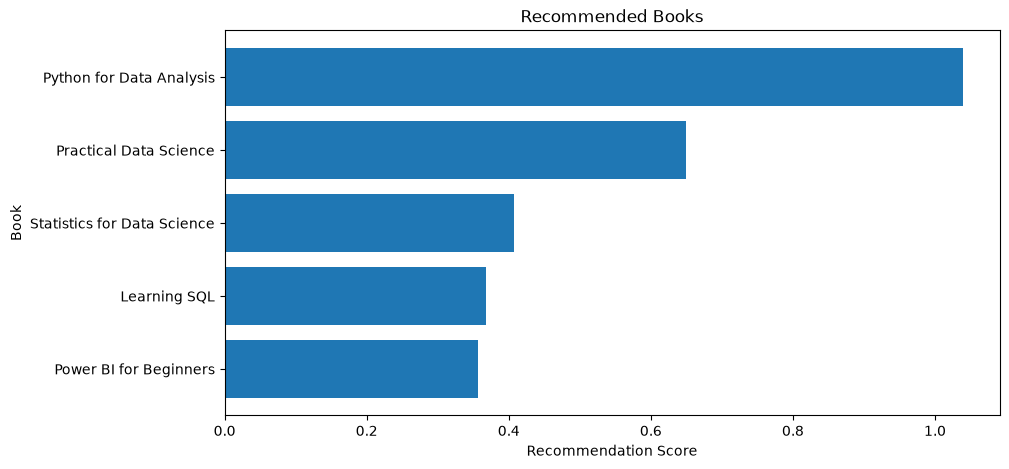

In [73]:
show_recommendation_dashboard(
    "I am a beginner and want to learn Python for data analysis"
)

Match Confidence: 0.684

Recommended Books:


,Title,Author,Subject,Difficulty,Available,Final_Score
8,Learning SQL,Alan Beaulieu,SQL,Beginner,Yes,0.934
2,Database System Concepts,Abraham Silberschatz,DBMS,Intermediate,No,0.345
0,Python for Data Analysis,Wes McKinney,Data Science,Beginner,Yes,0.250
12,Power BI for Beginners,Mike Carlo,Data Analytics,Beginner,Yes,0.250
14,Practical Data Science,Nina Zumel,Data Science,Beginner,Yes,0.250


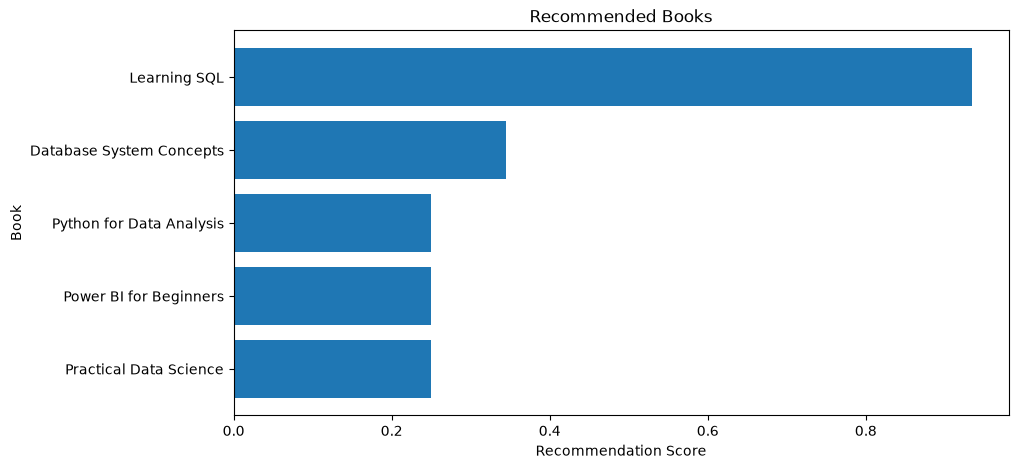

In [74]:
show_recommendation_dashboard(
    "I need an easy book for SQL and databases"
)

Match Confidence: 0.684

Recommended Books:


,Title,Author,Subject,Difficulty,Available,Final_Score
8,Learning SQL,Alan Beaulieu,SQL,Beginner,Yes,0.934
2,Database System Concepts,Abraham Silberschatz,DBMS,Intermediate,No,0.345
0,Python for Data Analysis,Wes McKinney,Data Science,Beginner,Yes,0.250
12,Power BI for Beginners,Mike Carlo,Data Analytics,Beginner,Yes,0.250
14,Practical Data Science,Nina Zumel,Data Science,Beginner,Yes,0.250


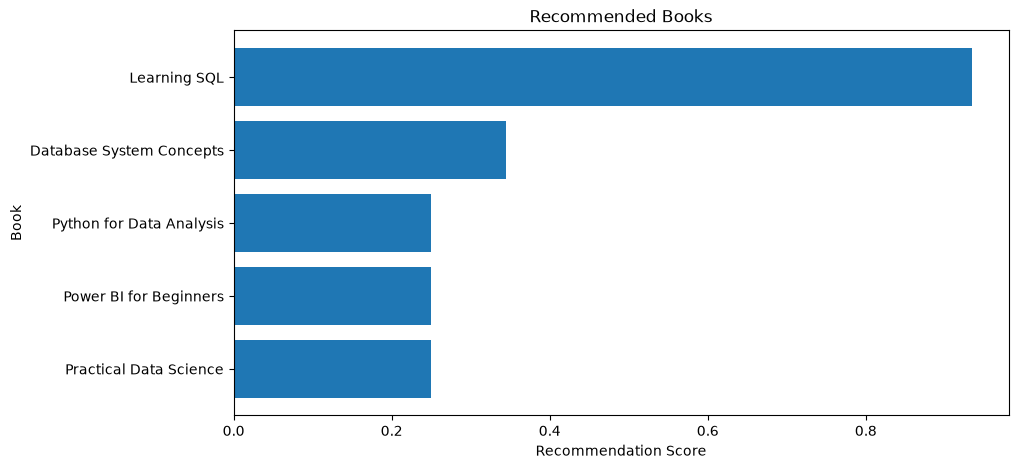

In [75]:
show_recommendation_dashboard(
    "I need an easy book for SQL and databases"
)

In [76]:
test_cases = [
    {
        "query": "I am a beginner and want to learn Python",
        "expected_difficulty": "Beginner",
        "expected_intent": "Learning"
    },
    {
        "query": "I have an exam tomorrow and need an easy book for SQL",
        "expected_difficulty": "Beginner",
        "expected_intent": "Exam Preparation"
    },
    {
        "query": "I need an advanced book for deep learning research",
        "expected_difficulty": "Advanced",
        "expected_intent": "Research"
    },
    {
        "query": "I need a practical book for a machine learning project",
        "expected_difficulty": None,
        "expected_intent": "Project"
    },
    {
        "query": "I want hands-on examples for SQL",
        "expected_difficulty": None,
        "expected_intent": "Practical Learning"
    }
]

print("Total Test Cases:", len(test_cases))

Total Test Cases: 5


In [77]:
for i, test in enumerate(test_cases, start=1):
    
    result = understand_query(test["query"])
    
    difficulty_correct = (
        result["difficulty"] == test["expected_difficulty"]
    )
    
    intent_correct = (
        result["intent"] == test["expected_intent"]
    )
    
    print(f"\nTest Case {i}")
    print("Query:", test["query"])
    print("Detected Difficulty:", result["difficulty"])
    print("Expected Difficulty:", test["expected_difficulty"])
    print("Difficulty Correct:", difficulty_correct)
    print("Detected Intent:", result["intent"])
    print("Expected Intent:", test["expected_intent"])
    print("Intent Correct:", intent_correct)


Test Case 1
Query: I am a beginner and want to learn Python
Detected Difficulty: Beginner
Expected Difficulty: Beginner
Difficulty Correct: True
Detected Intent: Learning
Expected Intent: Learning
Intent Correct: True

Test Case 2
Query: I have an exam tomorrow and need an easy book for SQL
Detected Difficulty: Beginner
Expected Difficulty: Beginner
Difficulty Correct: True
Detected Intent: Exam Preparation
Expected Intent: Exam Preparation
Intent Correct: True

Test Case 3
Query: I need an advanced book for deep learning research
Detected Difficulty: Advanced
Expected Difficulty: Advanced
Difficulty Correct: True
Detected Intent: Learning
Expected Intent: Research
Intent Correct: False

Test Case 4
Query: I need a practical book for a machine learning project
Detected Difficulty: None
Expected Difficulty: None
Difficulty Correct: True
Detected Intent: Learning
Expected Intent: Project
Intent Correct: False

Test Case 5
Query: I want hands-on examples for SQL
Detected Difficulty: None

In [78]:
for i, test in enumerate(test_cases, start=1):
    
    print("\n" + "=" * 70)
    print(f"TEST CASE {i}")
    print("=" * 70)
    
    library_assistant(test["query"], top_n=3)


TEST CASE 1
        COGNITIVE LIBRARY ASSISTANT

Student Query:
I am a beginner and want to learn Python

Query Understanding:
Difficulty: Beginner
Intent: Learning
Practical Preference: False
Match Confidence: 0.447

Recommended Books:

1. Python for Data Analysis
   Author: Wes McKinney
   Subject: Data Science
   Difficulty: Beginner
   Available: Yes
   Score: 0.697
   Why recommended: matches your requested beginner level; currently available; matches topics such as python

2. Practical Data Science
   Author: Nina Zumel
   Subject: Data Science
   Difficulty: Beginner
   Available: Yes
   Score: 0.409
   Why recommended: matches your requested beginner level; currently available; matches topics such as python

3. Natural Language Processing with Python
   Author: Steven Bird
   Subject: NLP
   Difficulty: Intermediate
   Available: Yes
   Score: 0.392
   Why recommended: currently available; matches topics such as python


TEST CASE 2
        COGNITIVE LIBRARY ASSISTANT

Student

In [80]:
def detect_intent(query):
    
    query = query.lower()

    if any(word in query for word in [
        "exam",
        "examination",
        "test",
        "revision"
    ]):
        return "Exam Preparation"

    elif any(word in query for word in [
        "project",
        "project work",
        "implementation"
    ]):
        return "Project"

    elif any(word in query for word in [
        "research",
        "research paper",
        "research work"
    ]):
        return "Research"

    elif any(word in query for word in [
        "practice",
        "practical",
        "examples",
        "hands-on"
    ]):
        return "Practical Learning"

    elif any(word in query for word in [
        "learn",
        "learning",
        "understand",
        "study"
    ]):
        return "Learning"

    else:
        return "General Search"

In [81]:
print(detect_intent("I want to study Python"))
print(detect_intent("I have an exam tomorrow"))
print(detect_intent("I need a machine learning project"))
print(detect_intent("I am doing AI research"))
print(detect_intent("I want hands-on SQL examples"))

Learning
Exam Preparation
Project
Research
Exam Preparation


In [82]:
!pip install streamlit

     ---------------------------------------- 0.0/44.3 kB ? eta -:--:--
     --------------------------- ------------ 30.7/44.3 kB 1.3 MB/s eta 0:00:01
     --------------------------- ------------ 30.7/44.3 kB 1.3 MB/s eta 0:00:01
     -------------------------------------- 44.3/44.3 kB 436.6 kB/s eta 0:00:00
   ---------------------------------------- 0.0/10.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.1 MB 660.6 kB/s eta 0:00:16
   ---------------------------------------- 0.1/10.1 MB 825.8 kB/s eta 0:00:13
   ---------------------------------------- 0.1/10.1 MB 655.4 kB/s eta 0:00:16
   ---------------------------------------- 0.1/10.1 MB 804.6 kB/s eta 0:00:13
    --------------------------------------- 0.2/10.1 MB 706.2 kB/s eta 0:00:15
    --------------------------------------- 0.2/10.1 MB 807.1 kB/s eta 0:00:13
    --------------------------------------- 0.2/10.1 MB 696.3 kB/s eta 0:00:15
    --------------------------------------- 0.2/10.1 MB 696.3 kB/


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [83]:
import streamlit as st

print("Streamlit installed successfully!")

Streamlit installed successfully!


In [84]:
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

import streamlit as st

In [85]:
df = pd.read_csv("Dataset/books.csv")

In [86]:
df["Book_Text"] = (
    df["Title"] + " " +
    df["Subject"] + " " +
    df["Description"] + " " +
    df["Keywords"]
)

df["Book_Text"] = df["Book_Text"].str.lower()

df["Book_Text"] = (
    df["Book_Text"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

In [87]:
vectorizer = TfidfVectorizer(stop_words="english")

tfidf_matrix = vectorizer.fit_transform(
    df["Book_Text"]
)